# 感度分析② 名目速度関数のパラメータ（1つずつ少しだけ動かす）

C-C ロジスティック（ub, uf, rhoc, theta1, theta2）と T-T Underwood（uf, rhoc）の7個を、**1つずつ** ±1%, ±5%, ±10% 動かし（他は基準のまま）、次を比べる。

- s の中央値・s>0 の割合、u* の中央値
- レジーム（2-pipe / 1-pipe / non-NE）の割合、協力性あり（s>0 かつ 2-pipe）の割合
- **判定の入れ替わり**: 基準と比べて、sの符号・レジーム・協力性の判定が変わったスナップショットの割合
- **フィットMAEの変化**（NGSIMミクロデータ）: 結果が大きく変わるのにMAEがほとんど変わらないパラメータ ＝ データで決まらないのに結論を左右する（見直し候補）

固定: a2, b1, eps = 2 km/h, printed 形, 先頭・末尾 100 秒除外。対象は両クラスがいるスナップショットだけ。

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

sys.path.append(os.path.abspath('..'))
from src.whole_pipeline import prepare_data, filter_invalid_headway, compute_micro_density
from src.sensitivity_scaling import pipeline_step3, check_against_pipeline
from src.sensitivity_nominal import *

In [2]:
# 名目速度関数（km単位）と a2, b1
paper_car = {'ub': 12.762, 'uf': 118.367, 'rhoc': 12.676, 'theta1': 4.995, 'theta2': 0.2309}
paper_trk = {'uf': 68.478, 'rhoc': 25.936}
own_car   = {'ub': 12.760, 'uf': 118.369, 'rhoc': 12.676, 'theta1': 4.999, 'theta2': 0.343}   # strong_constraint
own_trk   = {'uf': 68.473, 'rhoc': 18.542}

# 基準点: 名前 → (car, truck, a2, b1)   すべて printed 形で計算する
bases = {
    'P (paper)':     (paper_car, paper_trk, 0.4528, 2.5996),
    'O (own)':       (own_car,   own_trk,   0.4687, 1.8331),
    # inverted(a2, b1) = printed(1/a2, 1/b1)。論文の数値がほぼ再現できる設定
    'P-inv (paper)': (paper_car, paper_trk, 1 / 0.4528, 1 / 2.5996),
}

EPS = 2.0                               # km/h
SKIP_WARMUP, SKIP_COOLDOWN = 100, 100   # notebook 05 と同じ

In [3]:
data = prepare_data()   # 1回だけ実行

(4566387, 19)



--フリッカリング除去--
補正されたブロック数: 671
行数: 4,566,387



--フリッカリング除去--
補正されたブロック数: 142
行数: 4,566,387



--フリッカリング補正行の車間距離を座標から再計算--
対象行: 3,225  再計算できた行: 2,472  NaNにした行: 753
  NaNの内訳: 先行車が別車線 345行 / 先行車なし・位置不明・距離0以下 408行
  元の値から1ft超変わった行: 2,284  (元の値が0だった行: 208)



--ペアIDを付与--
総行数: 4,566,387
追従ペア数: 13,827


...


--車種フィルタ(1,2,3,4の追従モードを残す)--
フィルタ前のペア数: 5,780
フィルタ後のペア数: 5,666
除外されたペア数: 114
フィルタ後行数: 2,335,438行

モードID別ペア数:


mode_id
1.0    5067
2.0     237
3.0     326
4.0      36
dtype: int64



--追従時間フィルタ--
フィルタ前のペア数: 5,666
フィルタ後のペア数: 1,570
除外されたペア数: 4,096
フィルタ前の行数: 2,335,438
フィルタ後の行数: 1,487,854



--カットオフウィンドウ--
カットオフ前の行数: 1,487,854
カットオフ後の行数: 1,173,854
除外された行数: 314,000
カットオフ前のペア数: 1,570
カットオフ後のペア数: 1,570

--加速度フィルタ--
フィルタ前の行数: 1,173,854
フィルタ後の行数: 881,448
除外された行数: 292,406
フィルタ前のペア数: 1,570
フィルタ後のペア数: 1,570


区間長: 545.8 m, 車線数: 3

--マクロ密度・平均速度を計算--


In [4]:
# フィットMAE用のミクロ密度データ（Step 1 と同じ前処理）
df_mdensity = compute_micro_density(filter_invalid_headway(data['df_final']))
mae_data = prepare_mae_data(df_mdensity)
{m: len(v[0]) for m, v in mae_data.items()}   # mode_id ごとの行数 (1:C-C, 2:C-T, 3:T-C, 4:T-T)


--閾値以下の車頭距離データを除外--
spacing <= 4.5m (14.76ft) の行を除外: 881,448 -> 878,738 (除外 2,710行)

--ミクロ密度を計算--


{1: 812689, 2: 36214, 3: 26059, 4: 3776}

### パイプラインとの一致確認
基準点と、パラメータを少し動かした組で、brentq版(`pipeline_step3`)と二分法版(`surplus_at`)が一致することを確認する。

In [5]:
for name, (car, trk, a2, b1) in bases.items():
    for key, fac in [(('car', 'ub'), 1.0), (('car', 'theta2'), 1.05), (('truck', 'rhoc'), 0.95)]:
        c, t = perturb(car, trk, key, fac)
        check_against_pipeline(data, c, t, 'printed', [(a2, b1)],
                               skip_sec_warmup=SKIP_WARMUP, skip_sec_cooldown=SKIP_COOLDOWN)

各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 30件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 4.97e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 15件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 5.01e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 30件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 5.01e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 4,079件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 4.83e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 4,173件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 4.80e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 3,592件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 4.94e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 4,989件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 4.97e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 4,974件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 5.01e-13)
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 4,989件）
パイプラインとの一致を確認 (scaling=printed, 1組, 最大差 4.76e-13)


### OAT表
観測状態（rho1, rho2, ũ1, ũ2）はパラメータに依存しないので、1回作って使い回す。

In [6]:
states = pipeline_step3(data, paper_car, paper_trk, 1.0, 1.0, 'printed',
                        skip_sec_warmup=SKIP_WARMUP, skip_sec_cooldown=SKIP_COOLDOWN)

oat = pd.concat([oat_table(states, car, trk, a2, b1, EPS, mae_data, base_name=name)
                 for name, (car, trk, a2, b1) in bases.items()], ignore_index=True)

# 基準点の値
oat[oat['param'] == 'base'][['base', 'n_judged', 's_median', 'frac_s_pos', 'u_median',
                             'share_2pipe', 'share_1pipe', 'share_coop',
                             'mae_cc', 'mae_ct', 'mae_tc', 'mae_tt']].round(4)

各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件


1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 2,130件）


,base,n_judged,s_median,frac_s_pos,u_median,share_2pipe,share_1pipe,share_coop,mae_cc,mae_ct,mae_tc,mae_tt
0,P (paper),4959,-0.0089,0.0000,28.3538,0.0000,0.0002,0.0000,8.4451,7.3549,14.0487,8.3369
43,O (own),4959,0.0032,0.8175,18.6931,0.4531,0.1331,0.4531,7.0494,6.7408,6.0989,5.7235
86,P-inv (paper),4959,0.1141,1.0000,23.8601,0.1127,0.0655,0.1127,8.4451,70.1655,11.8816,8.3369


### 一覧表: ±1%, ±5%, ±10% で判定がどれだけ入れ替わるか
- `flip_*` : 判定が変わったスナップショットの割合（0〜1）
- `d_*` : 基準からの差（割合は0〜1、u は km/h）
- `d_mae_own` : そのパラメータが効く追従タイプのMAEの変化の合計（C-Cのパラメータは C-C+C-T、T-Tは T-T+T-C、km/h）
- ＋側と−側のうち、絶対値の大きい方を表示

In [7]:
pd.set_option('display.width', 250)
for name in bases:
    d = oat[oat['base'] == name]
    print(f'===== {name} =====')
    display(pd.concat([flip_summary(d, p) for p in (1, 5, 10)], axis=1).round(3))

===== P (paper) =====


,flip_s_sign (±1%),flip_regime (±1%),flip_coop (±1%),d_frac_s_pos (±1%),d_share_2pipe (±1%),d_share_coop (±1%),d_u_median (±1%),d_mae_own (±1%),flip_s_sign (±5%),flip_regime (±5%),...,d_u_median (±5%),d_mae_own (±5%),flip_s_sign (±10%),flip_regime (±10%),flip_coop (±10%),d_frac_s_pos (±10%),d_share_2pipe (±10%),d_share_coop (±10%),d_u_median (±10%),d_mae_own (±10%)
param,,,,,,,,,,,,,,,,,,,,,
C-C ub,0.0,0.0,0.0,0.0,0.0,0.0,-0.101,0.117,0.0,0.001,...,-0.507,0.607,0.0,0.002,0.0,0.0,0.000,0.0,-1.015,1.260
C-C uf,0.0,0.0,0.0,0.0,0.0,0.0,-0.163,0.071,0.0,0.004,...,-0.819,0.361,0.0,0.013,0.0,0.0,0.001,0.0,-1.646,0.738
C-C rhoc,0.0,0.0,0.0,0.0,0.0,0.0,0.085,0.037,0.0,0.001,...,0.431,0.188,0.0,0.004,0.0,0.0,0.000,0.0,0.873,0.387
C-C theta1,0.0,0.0,0.0,0.0,0.0,0.0,-0.279,0.134,0.0,0.005,...,-1.400,0.708,0.0,0.032,0.0,0.0,0.006,0.0,-2.813,1.509
C-C theta2,0.0,0.0,0.0,0.0,0.0,0.0,0.281,0.135,0.0,0.005,...,1.452,0.750,0.0,0.026,0.0,0.0,0.004,0.0,3.032,1.703
T-T uf,0.0,0.0,0.0,0.0,0.0,0.0,-0.019,0.358,0.0,0.000,...,-0.103,1.806,0.0,0.001,0.0,0.0,0.000,0.0,-0.224,3.647
T-T rhoc,0.0,0.0,0.0,0.0,0.0,0.0,-0.017,-0.332,0.0,0.000,...,-0.088,-1.671,0.0,0.000,0.0,0.0,0.000,0.0,-0.185,-3.354


===== O (own) =====


,flip_s_sign (±1%),flip_regime (±1%),flip_coop (±1%),d_frac_s_pos (±1%),d_share_2pipe (±1%),d_share_coop (±1%),d_u_median (±1%),d_mae_own (±1%),flip_s_sign (±5%),flip_regime (±5%),...,d_u_median (±5%),d_mae_own (±5%),flip_s_sign (±10%),flip_regime (±10%),flip_coop (±10%),d_frac_s_pos (±10%),d_share_2pipe (±10%),d_share_coop (±10%),d_u_median (±10%),d_mae_own (±10%)
param,,,,,,,,,,,,,,,,,,,,,
C-C ub,0.006,0.017,0.012,-0.006,-0.012,-0.012,-0.114,0.054,0.046,0.077,...,-0.570,0.287,0.100,0.161,0.110,-0.100,-0.108,-0.110,-1.141,0.626
C-C uf,0.002,0.011,0.008,0.002,-0.008,-0.008,-0.063,0.003,0.010,0.042,...,-0.316,0.018,0.029,0.093,0.076,-0.029,-0.069,-0.076,-0.634,0.043
C-C rhoc,0.000,0.008,0.006,0.000,-0.006,-0.006,0.049,0.002,0.006,0.035,...,0.249,0.012,0.015,0.072,0.056,-0.015,-0.053,-0.056,0.508,0.030
C-C theta1,0.003,0.021,0.016,0.003,-0.016,-0.016,0.162,0.001,0.038,0.115,...,0.821,0.019,0.316,0.231,0.307,-0.316,-0.166,-0.307,1.662,0.081
C-C theta2,0.003,0.021,0.016,0.003,-0.016,-0.016,0.164,0.001,0.043,0.121,...,0.865,0.023,0.420,0.256,0.360,-0.420,-0.184,-0.360,1.852,0.104
T-T uf,0.009,0.002,0.001,0.009,-0.001,-0.001,-0.010,0.021,0.069,0.007,...,-0.053,0.143,0.494,0.013,0.280,-0.494,0.010,-0.267,-0.112,0.374
T-T rhoc,0.011,0.002,0.001,0.011,-0.001,-0.001,-0.013,0.006,0.098,0.009,...,-0.067,0.142,0.818,0.015,0.453,-0.818,0.012,-0.453,-0.141,0.530


===== P-inv (paper) =====


,flip_s_sign (±1%),flip_regime (±1%),flip_coop (±1%),d_frac_s_pos (±1%),d_share_2pipe (±1%),d_share_coop (±1%),d_u_median (±1%),d_mae_own (±1%),flip_s_sign (±5%),flip_regime (±5%),...,d_u_median (±5%),d_mae_own (±5%),flip_s_sign (±10%),flip_regime (±10%),flip_coop (±10%),d_frac_s_pos (±10%),d_share_2pipe (±10%),d_share_coop (±10%),d_u_median (±10%),d_mae_own (±10%)
param,,,,,,,,,,,,,,,,,,,,,
C-C ub,0.0,0.005,0.002,0.0,0.002,0.002,-0.090,0.113,0.0,0.030,...,-0.425,0.574,0.0,0.060,0.023,0.0,0.023,0.023,-0.844,1.168
C-C uf,0.0,0.006,0.003,0.0,0.003,0.003,-0.098,0.846,0.0,0.040,...,-0.470,4.234,0.0,0.080,0.034,0.0,0.034,0.034,-0.949,8.480
C-C rhoc,0.0,0.003,0.001,0.0,0.001,0.001,-0.052,-0.327,0.0,0.020,...,-0.243,-1.639,0.0,0.040,0.017,0.0,0.017,0.017,-0.477,-3.279
C-C theta1,0.0,0.016,0.007,0.0,0.007,0.007,-0.190,-0.256,0.0,0.073,...,-0.935,-1.287,0.0,0.163,0.063,0.0,0.063,0.063,-1.885,-2.591
C-C theta2,0.0,0.016,0.007,0.0,0.007,0.007,-0.189,0.345,0.0,0.071,...,-0.890,1.781,0.0,0.146,0.056,0.0,0.056,0.056,1.813,3.716
T-T uf,0.0,0.007,0.004,0.0,0.004,0.004,-0.071,0.116,0.0,0.038,...,-0.390,0.584,0.0,0.071,0.034,0.0,0.034,0.034,-0.832,1.182
T-T rhoc,0.0,0.007,0.003,0.0,0.003,0.003,-0.074,-0.109,0.0,0.037,...,-0.408,-0.555,0.0,0.070,0.034,0.0,0.034,0.034,-0.863,-1.115


### 図: 判定の入れ替わりとMAEの変化（±1%, ±5%）

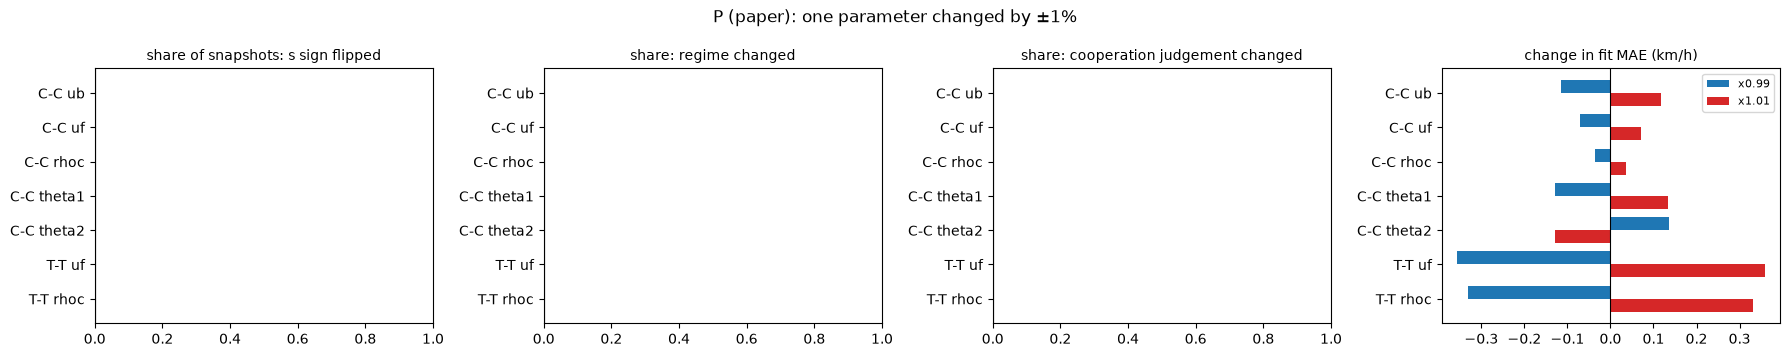

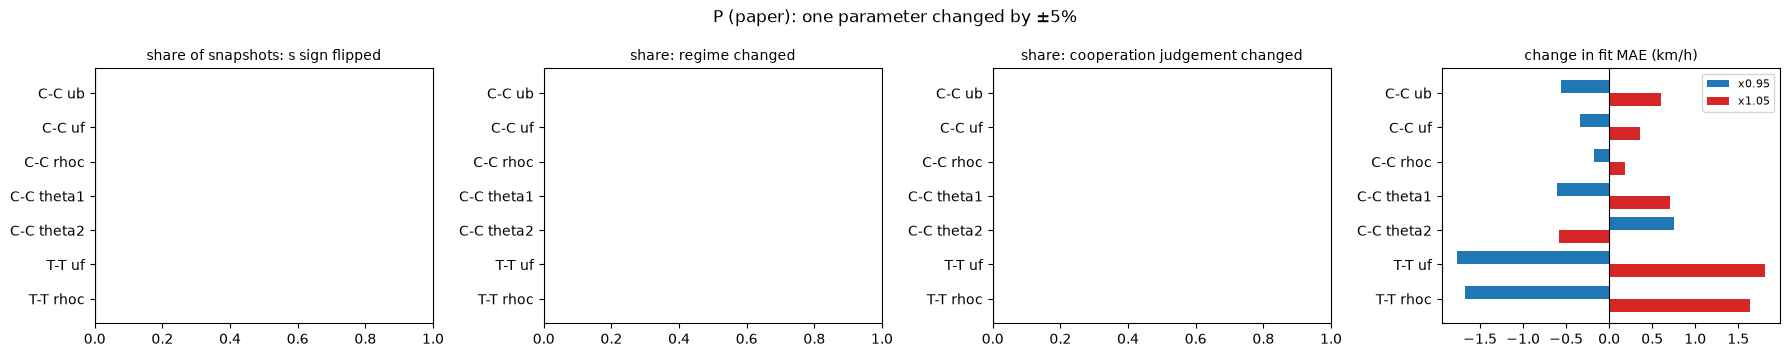

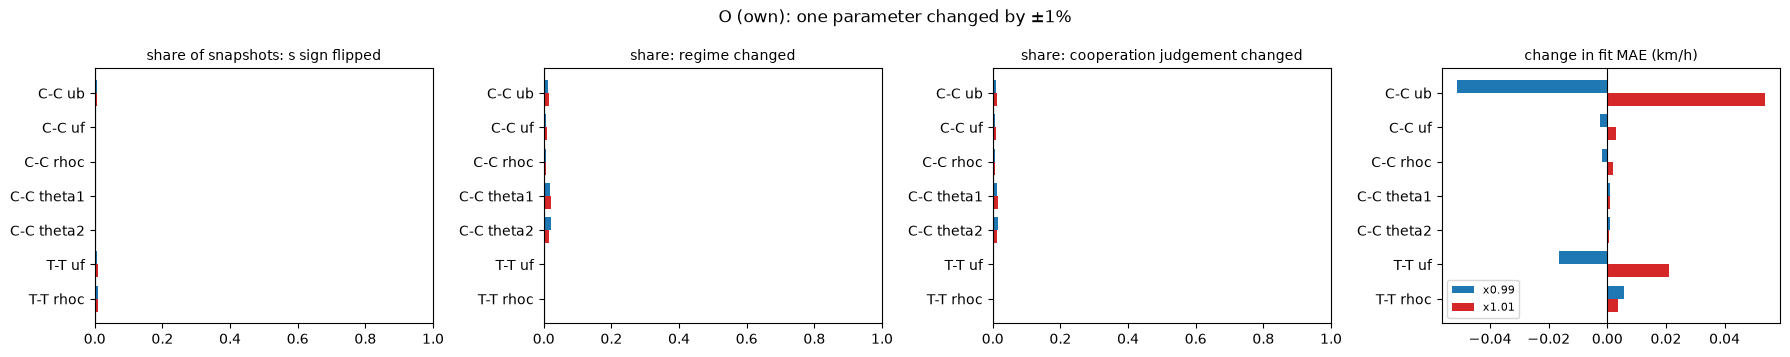

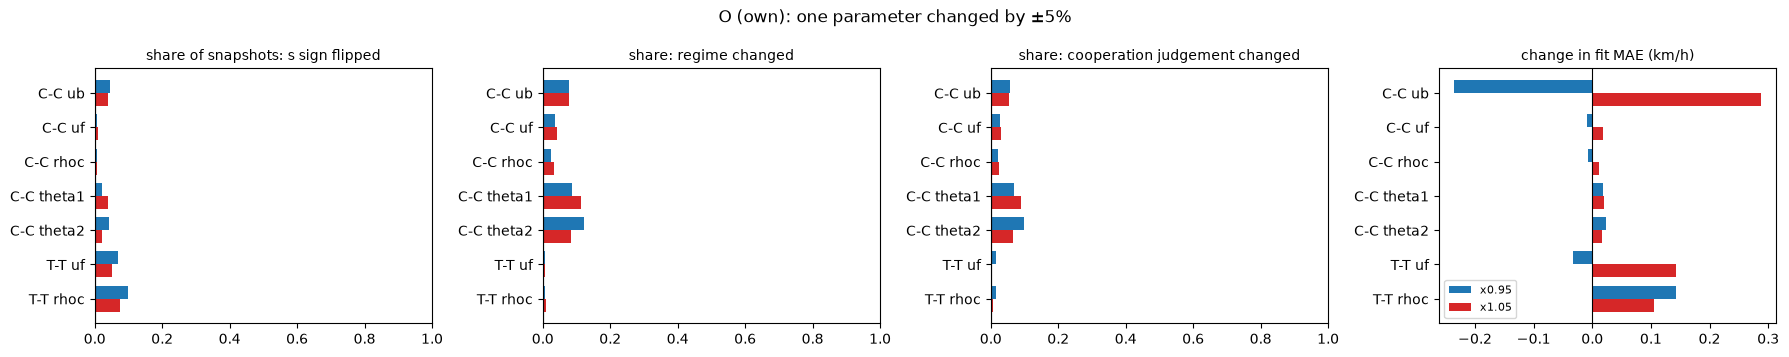

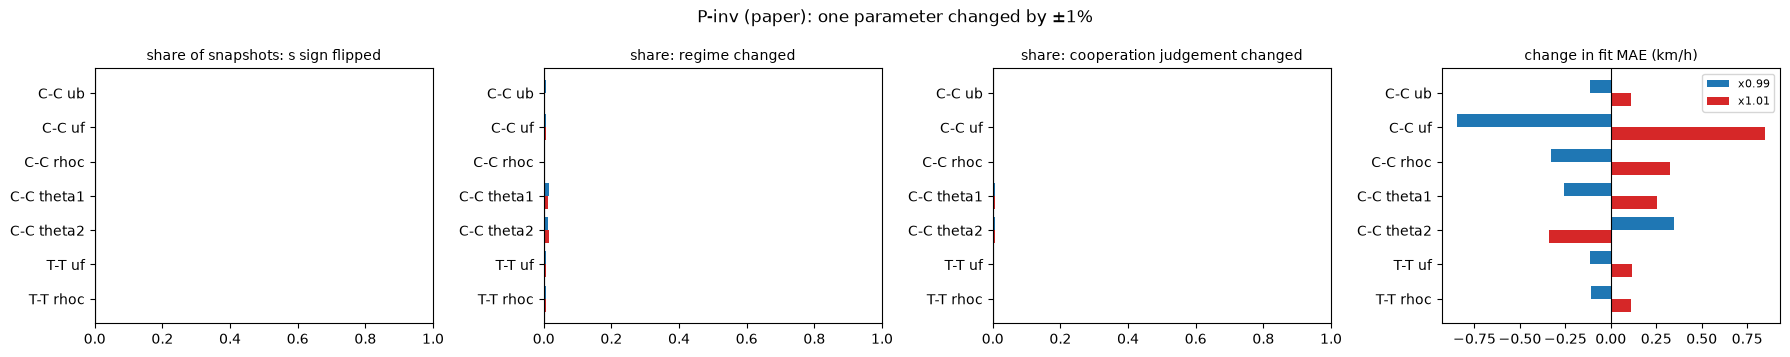

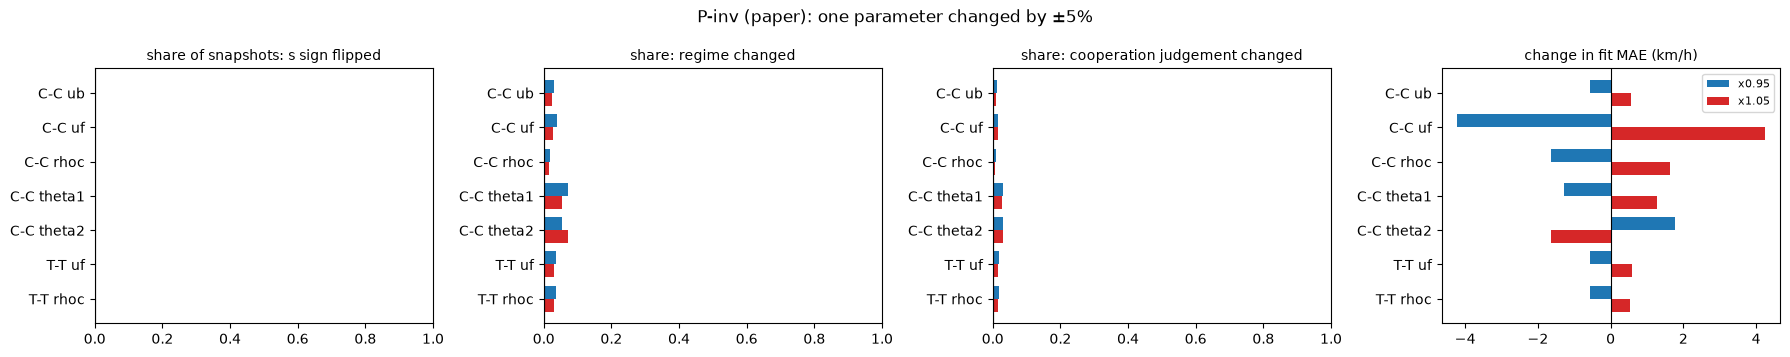

In [8]:
for name in bases:
    for pct in (1, 5):
        plot_flip_bars(oat[oat['base'] == name], pct, title=f'{name}: one parameter changed by ±{pct}%')
        plt.show()

### 図: 結果の変化 vs MAEの変化
左上（MAEはほとんど変わらないのに判定が大きく変わる）にあるパラメータが見直し候補。

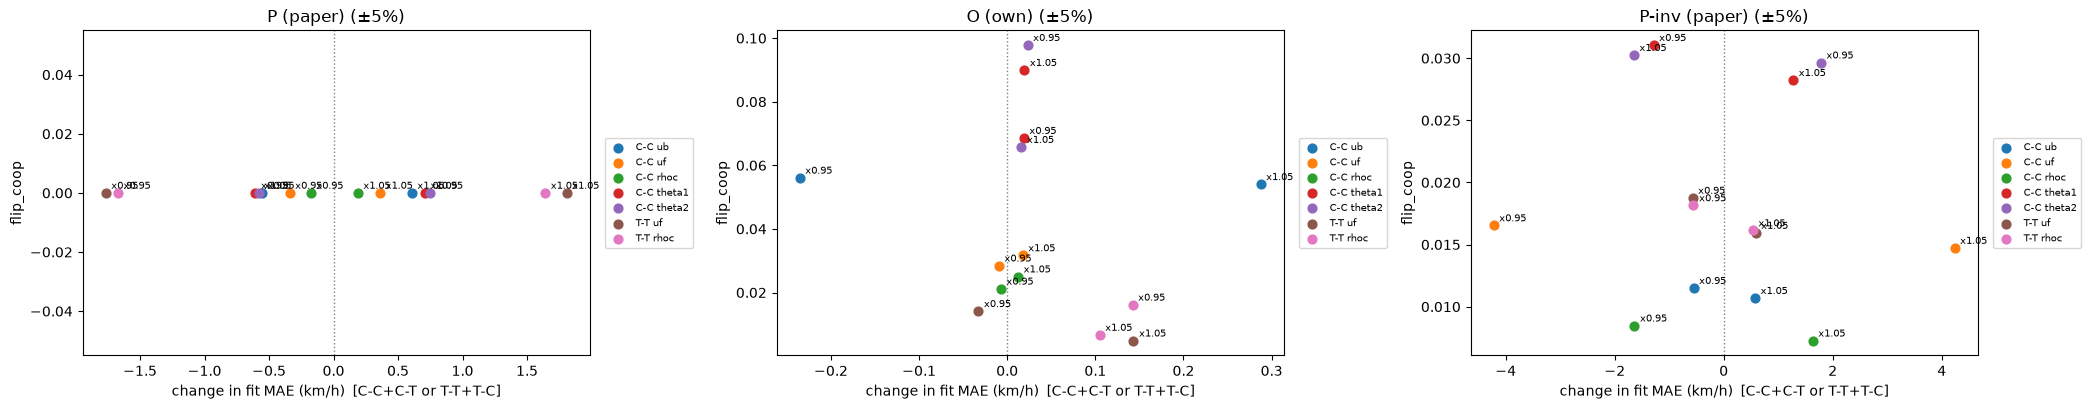

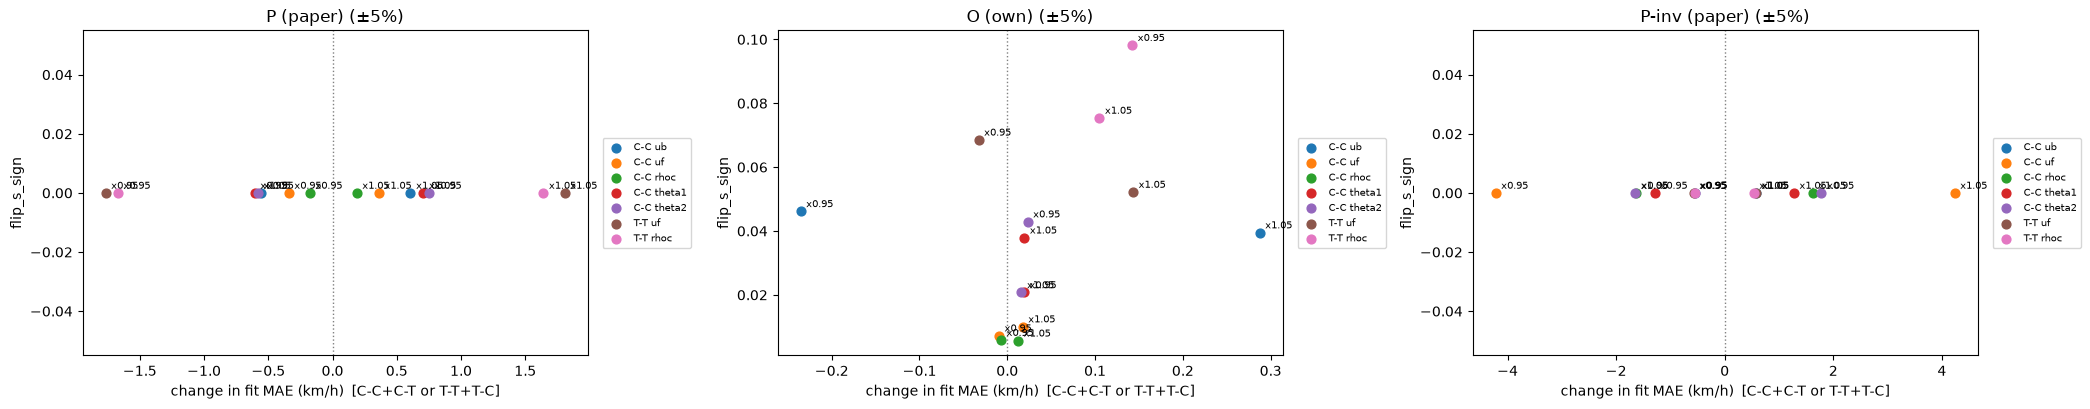

In [9]:
for effect in ['flip_coop', 'flip_s_sign']:
    fig, axs = plt.subplots(1, len(bases), figsize=(7 * len(bases), 4.2))
    for ax, name in zip(axs, bases):
        plot_effect_vs_mae(oat[oat['base'] == name], effect=effect, pct=5, ax=ax, title=f'{name} (±5%)')
    fig.tight_layout()
    plt.show()

### 図: 倍率に対する変化（−10%〜+10%）

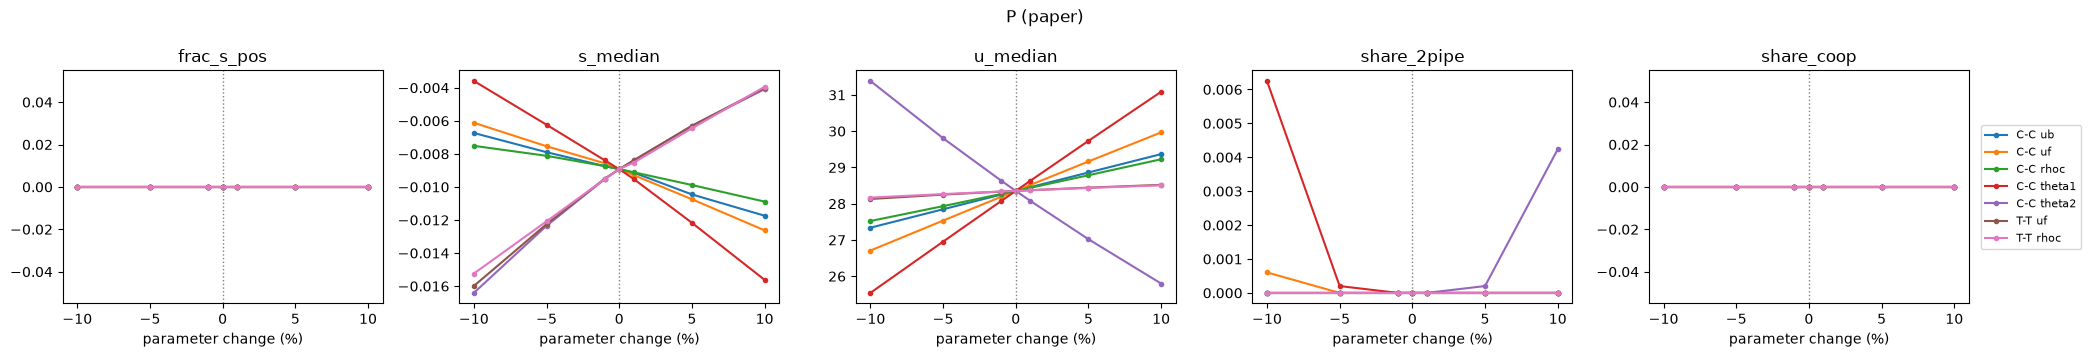

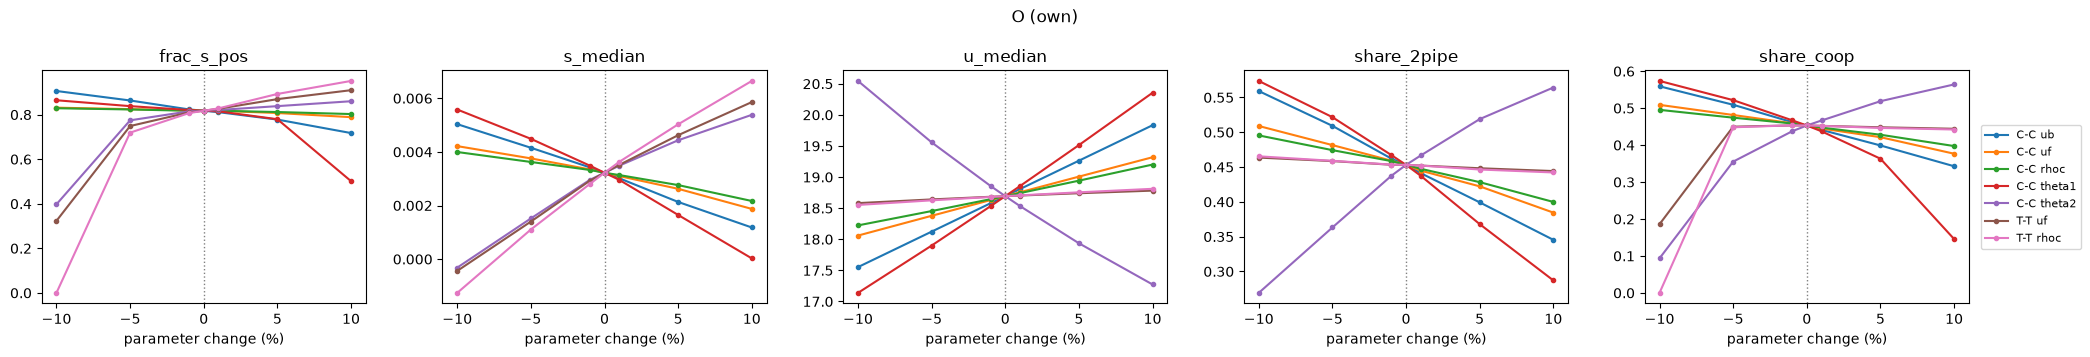

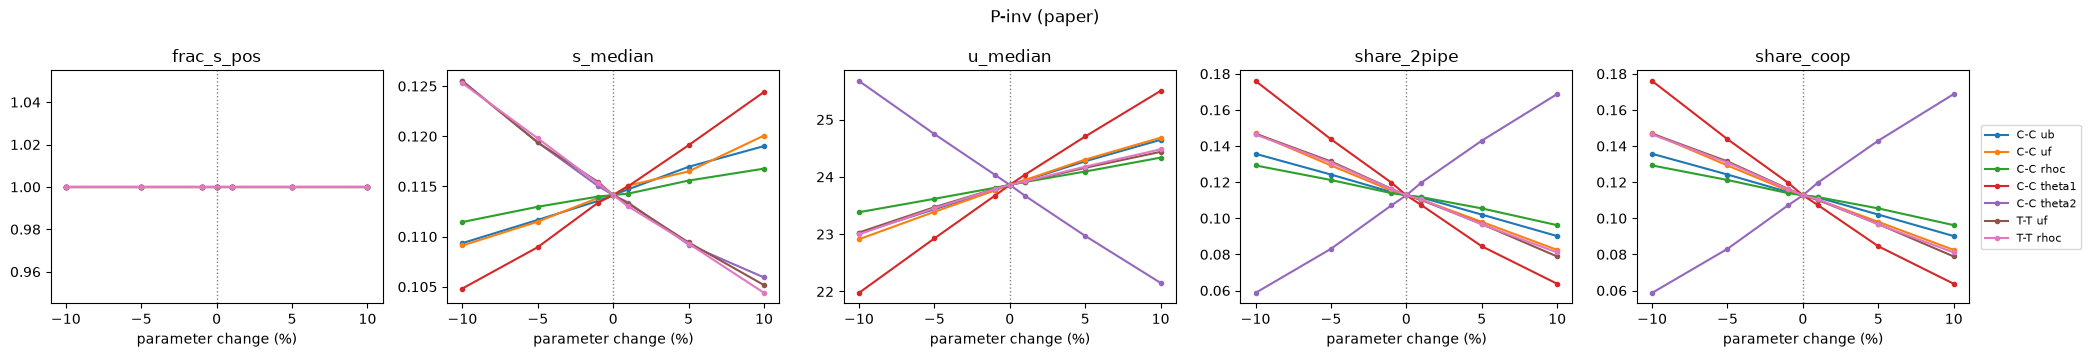

In [10]:
for name in bases:
    plot_oat_lines(oat[oat['base'] == name], ['frac_s_pos', 's_median', 'u_median', 'share_2pipe', 'share_coop'],
                   title=name)
    plt.show()

---
## ゼミ用の図（2026-10-22）
図は `results/seminar_2026-10-22/` にPNGでも保存する。

In [11]:
from src.sensitivity_scaling import log_grid, sweep_scaling, plot_sweep, surplus_map, plot_surplus_map

FIG_DIR = os.path.abspath(os.path.join('..', 'results', 'seminar_2026-10-22'))
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches='tight')

### ① (a2, b1) 平面の s>0 の割合（感度分析①、notebook 05 と同じ計算）

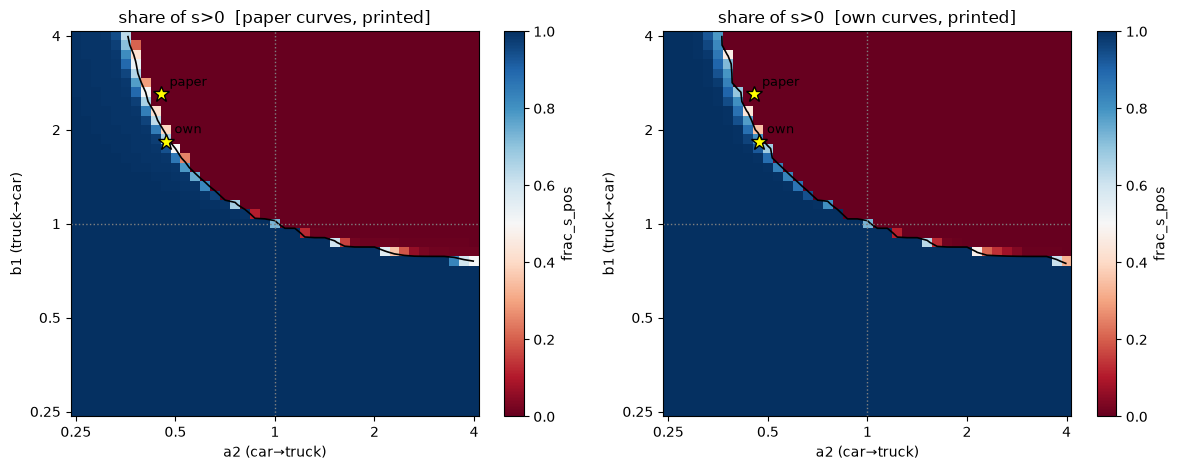

In [12]:
marks = {'paper': (0.4528, 2.5996), 'own': (0.4687, 1.8331)}
grid = log_grid(0.25, 4.0, 41)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, car, trk) in zip(axs, [('paper', paper_car, paper_trk), ('own', own_car, own_trk)]):
    sw = sweep_scaling(states, car, trk, 'printed', grid, grid)
    plot_sweep(sw, 'frac_s_pos', ax=ax, marks=marks, center=0.5, title=f'share of s>0  [{name} curves, printed]')
fig.tight_layout()
save(fig, 'sa1_ab_frac_s_pos.png')
plt.show()

### ② (rho1, rho2) 平面の s の地図（自前の値、黒点 = 観測スナップショット）

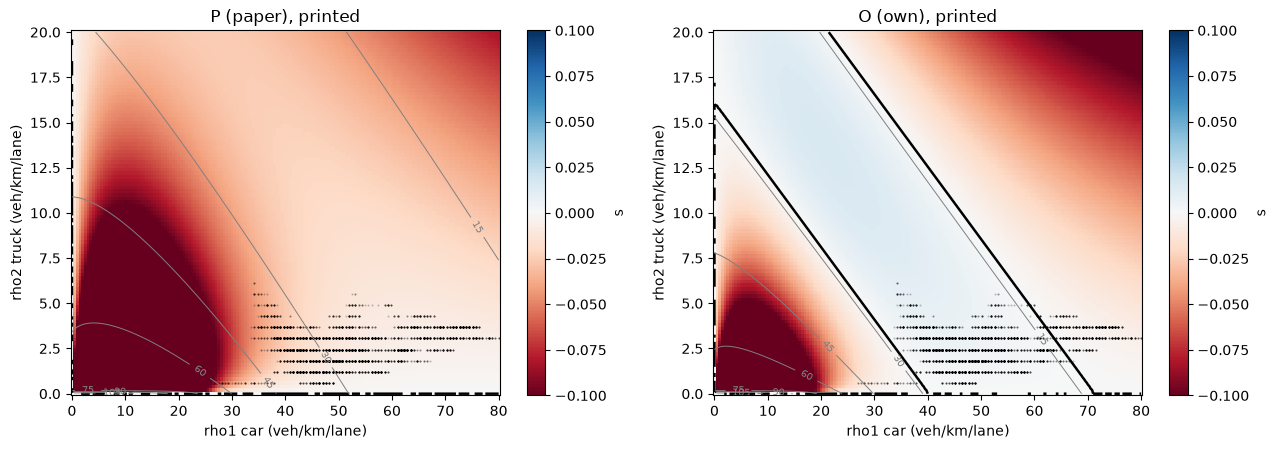

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (name, (car, trk, a2, b1)) in zip(axs, [(n, bases[n]) for n in ['P (paper)', 'O (own)']]):
    m = surplus_map(car, trk, a2, b1, 'printed', rho1_max=80, rho2_max=20)
    plot_surplus_map(m, states=states, ax=ax, smax=0.1, title=f'{name}, printed')
fig.tight_layout()
save(fig, 'sa1_rho_map.png')
plt.show()

### ③ 3つの基準点の s の分布
O だけが s=0 のすぐ近くにある → わずかなずれで符号が入れ替わる。

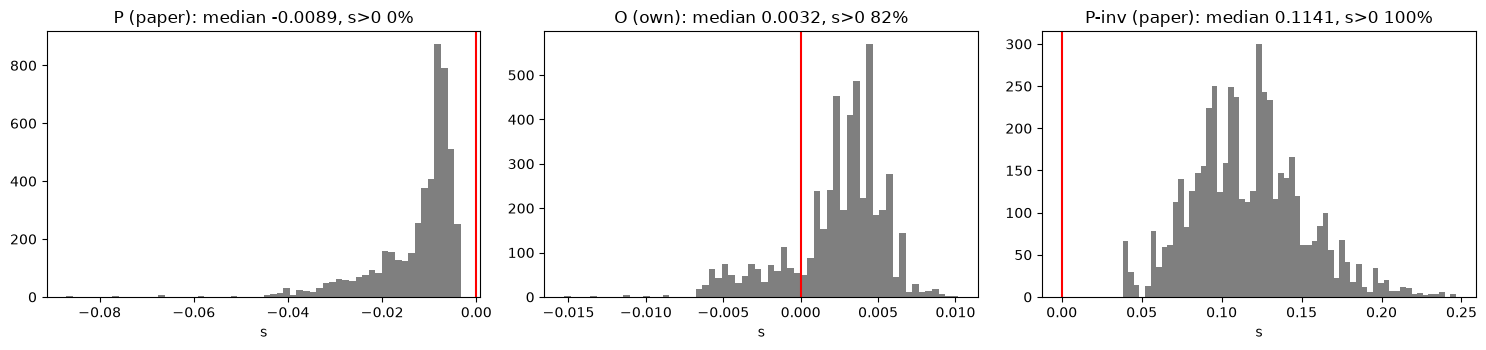

In [14]:
states_both = states[(states['rho1'] > 0) & (states['rho2'] > 0)]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (name, (car, trk, a2, b1)) in zip(axs, bases.items()):
    s = evaluate(states_both, car, trk, a2, b1, EPS)['s']
    s = s[np.isfinite(s)]
    ax.hist(s, bins=60, color='tab:gray')
    ax.axvline(0, color='r', lw=1.5)
    ax.set_title(f'{name}: median {np.median(s):.4f}, s>0 {np.mean(s > 0):.0%}')
    ax.set_xlabel('s')
fig.tight_layout()
save(fig, 'sa2_s_hist_bases.png')
plt.show()

### ④ 判定の入れ替わり（±10%）と、結果の変化 vs MAEの変化（±10%）

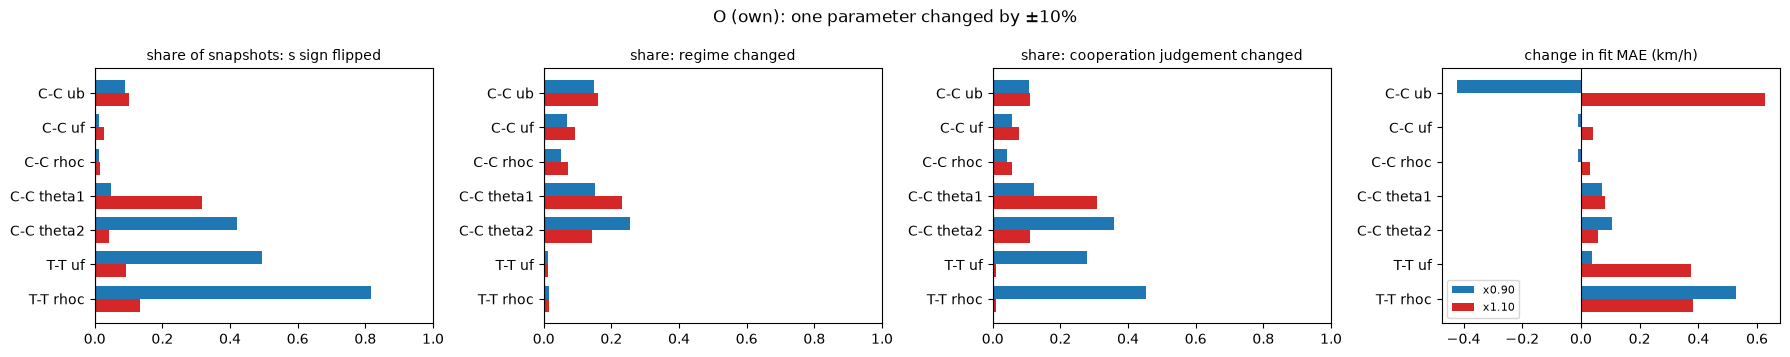

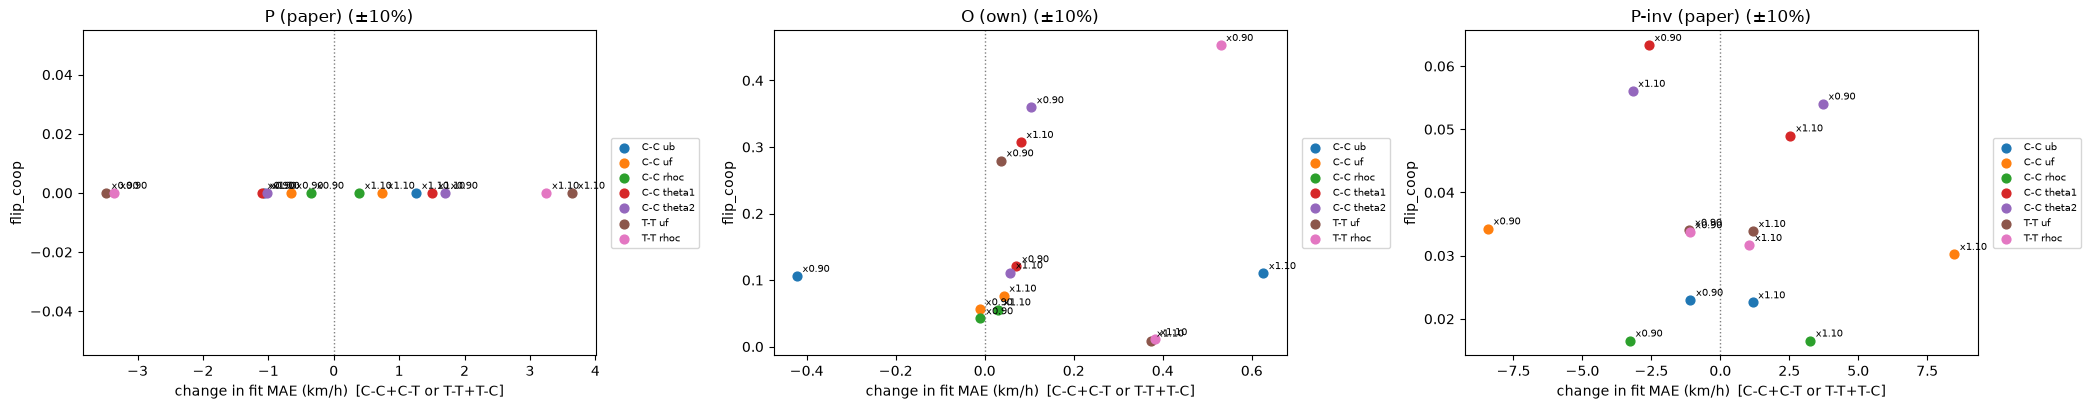

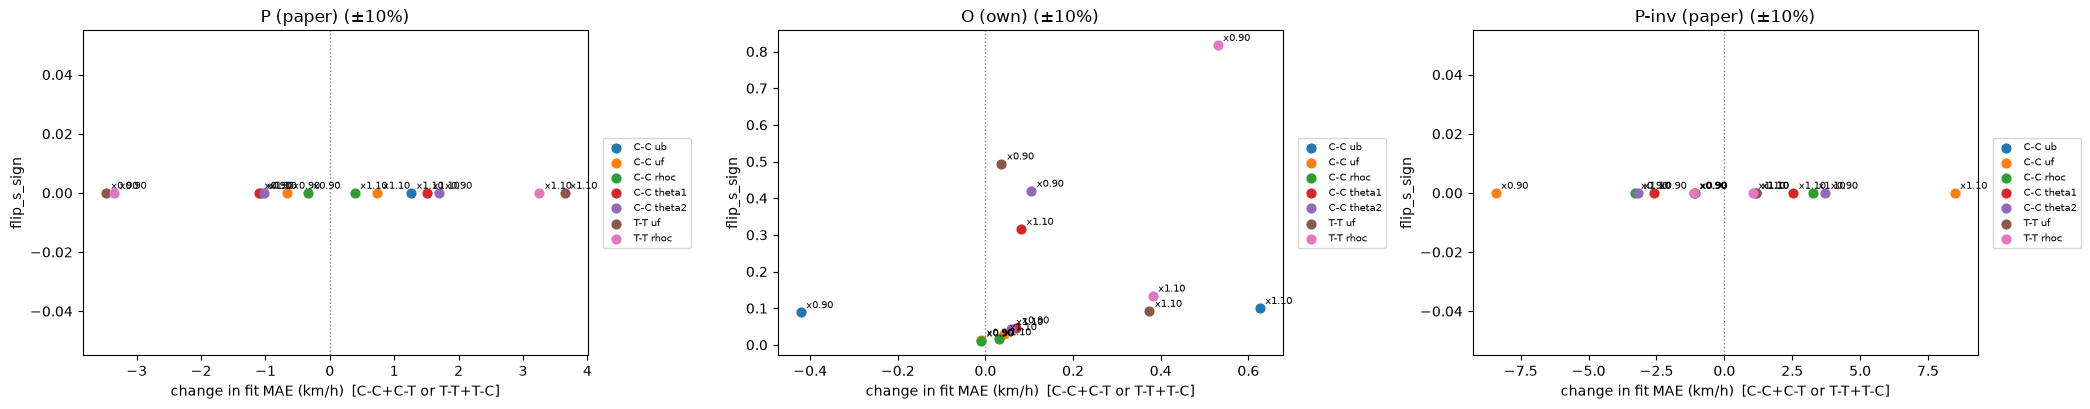

In [15]:
fig = plot_flip_bars(oat[oat['base'] == 'O (own)'], 10, title='O (own): one parameter changed by ±10%')
save(fig, 'sa2_O_flip_bars_10pct.png')
plt.show()

for effect in ['flip_coop', 'flip_s_sign']:
    fig, axs = plt.subplots(1, len(bases), figsize=(7 * len(bases), 4.2))
    for ax, name in zip(axs, bases):
        plot_effect_vs_mae(oat[oat['base'] == name], effect=effect, pct=10, ax=ax, title=f'{name} (±10%)')
    fig.tight_layout()
    save(fig, f'sa2_{effect}_vs_mae_10pct.png')
    plt.show()

### ⑤ eps を変えても結論が変わらないか（1, 2, 5 km/h、±10%）
s・u* は eps に依存しないので、変わりうるのはレジームと協力性の判定だけ。

In [16]:
eps_rows = []
for eps in [1.0, 2.0, 5.0]:
    for name, (car, trk, a2, b1) in bases.items():
        d = oat_table(states, car, trk, a2, b1, eps, mae_data, factors=(0.90, 1.10), base_name=name)
        b = d[d['param'] == 'base'].iloc[0]
        fs = flip_summary(d, 10)[['flip_regime (±10%)', 'flip_coop (±10%)']]
        eps_rows.append(pd.DataFrame({
            'eps': eps, 'base': name, 'param': fs.index,
            'share_2pipe_base': b['share_2pipe'], 'share_coop_base': b['share_coop'],
            'flip_regime': fs['flip_regime (±10%)'].values, 'flip_coop': fs['flip_coop (±10%)'].values,
        }))
eps_check = pd.concat(eps_rows, ignore_index=True)

# 基準点での割合
display(eps_check.groupby(['base', 'eps'])[['share_2pipe_base', 'share_coop_base']].first().round(3).unstack('eps'))
# ±10% で協力性の判定が変わった割合（パラメータ × eps）
display(eps_check.pivot_table(index=['base', 'param'], columns='eps', values='flip_coop', sort=False).round(3))

share_2pipe_base               share_coop_base              
eps                        1.0    2.0    5.0             1.0    2.0    5.0
base                                                                      
O (own)                  0.477  0.453  0.222           0.477  0.453  0.222
P (paper)                0.000  0.000  0.000           0.000  0.000  0.000
P-inv (paper)            0.123  0.113  0.044           0.123  0.113  0.044

eps                         1.0    2.0    5.0
base          param                          
P (paper)     C-C ub      0.000  0.000  0.000
              C-C uf      0.000  0.000  0.000
              C-C rhoc    0.000  0.000  0.000
              C-C theta1  0.000  0.000  0.000
              C-C theta2  0.000  0.000  0.000
              T-T uf      0.000  0.000  0.000
              T-T rhoc    0.000  0.000  0.000
O (own)       C-C ub      0.103  0.110  0.087
              C-C uf      0.062  0.076  0.066
              C-C rhoc    0.044  0.056  0.046
              C-C theta1  0.306  0.307  0.171
              C-C theta2  0.368  0.360  0.191
              T-T uf      0.282  0.280  0.158
              T-T rhoc    0.477  0.453  0.222
P-inv (paper) C-C ub      0.021  0.023  0.016
              C-C uf      0.027  0.034  0.023
              C-C rhoc    0.015  0.017  0.010
              C-C theta1  0.064  0.063  0.046
              C-C theta2  0.058  0.056  0.039
              T-T uf      0.030  0.034  0.025
              T-T rhoc    0.030  0.034  0.023

### ⑥ s=0 の境界と理論式の比較（Li 2022 との関係）
printed形の Eq.7 から恒等的に
$s = \frac{\rho_1\rho_2}{\rho_{tot}}\left[\frac{1/a_2-1}{R_1(u^*)} + \frac{1/b_1-1}{R_2(u^*)}\right]$（$R_i = u_i^{-1}$）なので、境界は
$1/a_2 - 1 = (1 - 1/b_1)\,\kappa(u^*)$、$\kappa = R_1/R_2$（同じ速度での車とトラックの密度の比）。

- Li (2022) のように基準の速度関数が共通なら $\kappa = 1$ → 境界は $1/a_2 + 1/b_1 = 2$（組成にも速度にも依存しない）
- Chen の設定（車: ロジスティック、トラック: Underwood）では $\kappa(u^*)$ が入る

確認すること: (1) 恒等式が数値で成り立つか、(2) スイープの境界（黒線）が $\kappa$ を定数にした理論式（緑）でどれだけ説明できるか、(3) Li の境界（赤）とどれだけずれるか。


In [17]:
from src.whole_pipeline import logistic_density_speed, underwood_density_speed
from src.sensitivity_scaling import boundary_b1_exact, plot_boundary_comparison, density_ratio

# (1) 恒等式の確認（基準点 O と P）
for name in ['P (paper)', 'O (own)']:
    car, trk, a2, b1 = bases[name]
    r = surplus_at(states_both, car, trk, a2, b1, 'printed')
    R1 = logistic_density_speed(r['u_1pipe'], **car)
    R2 = underwood_density_speed(r['u_1pipe'], **trk)
    rho1, rho2 = states_both['rho1'].values, states_both['rho2'].values
    s_id = rho1 * rho2 / (rho1 + rho2) * ((1 / a2 - 1) / R1 + (1 / b1 - 1) / R2)
    k = R1 / R2
    print(f'{name}: 恒等式の最大差 {np.nanmax(np.abs(s_id - r["s"])):.1e},  '
          f'kappa(u*) 中央値 {np.nanmedian(k):.2f} (10-90%: {np.nanquantile(k, 0.1):.2f}-{np.nanquantile(k, 0.9):.2f}),  '
          f'Liの基準 1/a2+1/b1-2 = {1 / a2 + 1 / b1 - 2:+.3f} (正ならLiではs>0)')

P (paper): 恒等式の最大差 6.0e-16,  kappa(u*) 中央値 2.36 (10-90%: 2.22-2.70),  Liの基準 1/a2+1/b1-2 = +0.593 (正ならLiではs>0)
O (own): 恒等式の最大差 8.0e-16,  kappa(u*) 中央値 2.30 (10-90%: 2.27-2.63),  Liの基準 1/a2+1/b1-2 = +0.679 (正ならLiではs>0)


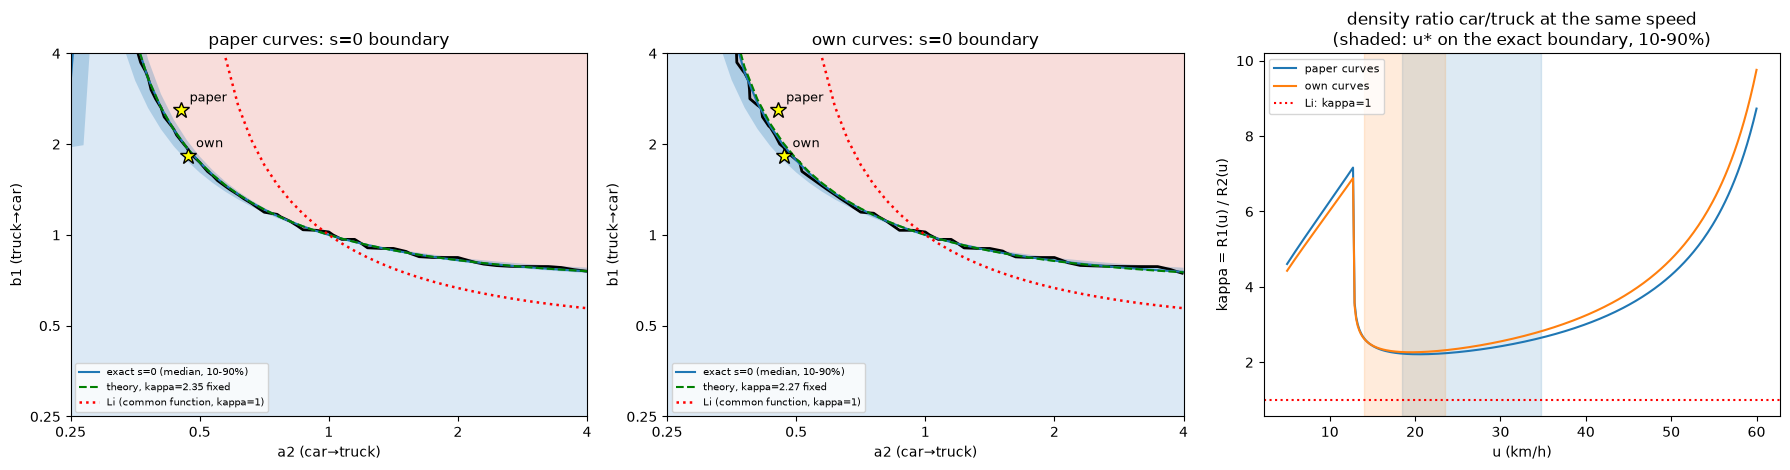

paper: kappa固定値 2.35,  境界上のkappa 中央値 2.36 (10-90%: 2.22-2.65)
own: kappa固定値 2.27,  境界上のkappa 中央値 2.31 (10-90%: 2.27-2.65)


In [18]:
a2_line = log_grid(0.25, 4.0, 41)
curves = {'paper': (paper_car, paper_trk), 'own': (own_car, own_trk)}
exacts, kappa_fixed = {}, {}
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (name, (car, trk)) in zip(axs, curves.items()):
    sw = sweep_scaling(states, car, trk, 'printed', grid, grid)
    exacts[name] = boundary_b1_exact(states, car, trk, a2_line)
    # kappa を定数にするときの値: スケーリングなし (a2=b1=1) での u* の中央値における kappa
    u0 = np.nanmedian(surplus_at(states_both, car, trk, 1.0, 1.0, 'printed')['u_1pipe'])
    kappa_fixed[name] = float(density_ratio(u0, car, trk))
    plot_boundary_comparison(sw, exacts[name], a2_line, kappa_fixed[name], ax=ax, marks=marks,
                             title=f'{name} curves: s=0 boundary')

# kappa(u) の形と、境界上の u* の範囲
u = np.linspace(5, 60, 300)
ax = axs[2]
for name, (car, trk) in curves.items():
    line, = ax.plot(u, density_ratio(u, car, trk), label=f'{name} curves')
    uq = np.nanquantile(exacts[name]['u_star'], [0.1, 0.9])
    ax.axvspan(*uq, color=line.get_color(), alpha=0.15)
ax.axhline(1, color='r', ls=':', label='Li: kappa=1')
ax.set_xlabel('u (km/h)')
ax.set_ylabel('kappa = R1(u) / R2(u)')
ax.set_title('density ratio car/truck at the same speed\n(shaded: u* on the exact boundary, 10-90%)')
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, 'sa1_boundary_vs_theory.png')
plt.show()

for name in curves:
    k = exacts[name]['kappa']
    print(f'{name}: kappa固定値 {kappa_fixed[name]:.2f},  境界上のkappa 中央値 {np.nanmedian(k):.2f} '
          f'(10-90%: {np.nanquantile(k, 0.1):.2f}-{np.nanquantile(k, 0.9):.2f})')